#  Исследование результатов А/В-теста и поиск инсайтов

В проекте - международное мобильное приложение для онлайн-торговли финансовыми активами. Пользователи могут инвестировать деньги в акции, валюту, криптовалюту, биржевые фонды (ETF) и другие активы. Целевая аудитория приложения — начинающие инвесторы. Получить доступ к финансовым рынкам можно со смартфона либо через веб-версию. 

Приложение ориентировано на рынок Латинской Америки с акцентом на четыре страны: Мексику, Бразилию, Колумбию и Аргентину — там быстро растёт интерес к финтеху и инвестициям, а экономики очень разные. 

Появилась гипотеза о недостаточной финансовой грамотности пользователей: они не понимают, как работать с активами разной степени риска. Клиенты покупают активы с высоким риском и теряют деньги, что снижает вовлечённость.
Команда продукта решила обновить онбординг пользователей и добавить в него детальную информацию о различиях финансовых активов и связанных с ними рисках. Однако появилось опасение, что углублённый онбординг отпугнёт клиентов от пополнения депозита и более рискованных вложений. 

Чтобы разобраться, команда решила провести A/B-эксперимент. 

### А/В-эксперимент

В эксперименте участвовали новые пользователи, которые зарегистрировались в приложении со 2 по 15 июня 2025 года. 
Пользователей случайным образом разделили на две равные группы: 
- Контрольная группа проходила стандартный онбординг без обязательного обучения.
- Тестовая группа проходила обновлённый онбординг с подробной информацией об активах и связанных с ними рисках. 

После разделения активность пользователей анализировали в течение недели.

Цель эксперимента — оценить, как обновлённый онбординг влияет на поведение пользователей и их дальнейшую инвестиционную активность.

При внедрении новой фичи команда продукта выдвинула такие гипотезы:
- Гипотеза роста: обучающий онбординг помогает пользователям лучше понимать принципы инвестирования, поэтому они будут чаще открывать второй депозит.
- Гипотеза риска: информация о возможных потерях и высоких рисках отпугнёт некоторых новичков, особенно самых осторожных, что снизит конверсию в первый депозит.
- Дополнительная гипотеза: после нового онбординга пользователи, которые выбрали высокорискованные активы, будут чаще, чем раньше, возвращаться и открывать второй депозит. При старом онбординге пользователи часто покупали активы с высоким риском без понимания последствий. Это приводило к потерям и оттоку после первого депозита. 

Чтобы увидеть полную картину, недостаточно следить за метриками конверсии. Команда выбрала для эксперимента такой набор метрик: 
- Ключевая метрика — средняя сумма всех депозитов на одного пользователя (включая тех, кто установил приложение или открыл веб-версию).
- Барьерная метрика — конверсия из регистрации в первый депозит.
- Вспомогательная метрика 1 — конверсия из первого депозита во второй.
- Вспомогательная метрика 2 — средняя сумма всех депозитов на пользователя, который открыл хотя бы один депозит.

Ожидалось, что ключевая и барьерная метрики не упадут, а вспомогательные покажут значительный рост. 

### Задачи

Предстоит провести полный анализ результатов А/В-эксперимента. Но перед этим нужно погрузиться в продукт и изучить исторические данные.    


#### Анализ исторических данных

- Поведение новых пользователей, в том числе динамику привлечения, сегментацию и ключевые этапы воронки действий.
- Метрики, связанные с внесением депозитов, в том числе средние суммы депозитов. 

#### Анализ данных А/В-теста

Изучение результатов эксперимента будет состоять из двух этапов: 
- Сравнение поведения пользователей в контрольной и тестовой группах, оценка статистической значимости изменений. 
- Исследование влияния нового онбординга на поведение платящих пользователей. В исследовании будем использовать бутстрап и сосредоточимся на нижних и верхних перцентилях распределения депозитов. 
- Такой подход позволит понять, как обновлённый онбординг повлиял на ключевые бизнес-метрики, найти точки роста и сформулировать рекомендации по улучшению пользовательского опыта и монетизации.

### Данные

Будем работать с двумя датасетами:  

1. Датасет `pa_sollmafin_hist.csv` содержит исторические данные о ключевых действиях новых пользователей, привлечённых в период с 1 апреля по 1 июня 2025 года включительно. В датасете собраны действия пользователей до оформления второго депозита. 
2. Датасет `pa_sollmafin_abt.csv` содержит данные А/В-эксперимента — все действия новых пользователей, которые зарегистрировались со 2 по 15 июня 2025 года включительно. Данные собраны в рамках проверки гипотезы о влиянии нового онбординга на поведение и активность пользователей. Пользователи уже распределены по группам А/В-эксперимента.

Общие поля датасетов:
- `user_id` — уникальный идентификатор пользователя;
- `country_code` — код страны пользователя в формате ISO (например, `BR` — Бразилия, `MX` — Мексика, `AR` — Аргентина, `CO` — Колумбия);
- `platform` — устройство, с которого пользователь взаимодействует с продуктом: mobile или web;
- `first_ts` — время первого появления пользователя в системе;
- `first_dt` — дата первого появления пользователя (без времени);
- `event_ts` — время события;
- `event_name` — название события;
- `amount` — сумма пополнения депозита;
- `asset` — тип приобретённого актива; 
- `risk_level` — уровень риска актива: low — низкий риск, medium — средний риск, high — высокий риск.

В датасете `pa_sollmafin_abt.csv` содержатся два дополнительных поля:
- `ab_test` — название А/В-эксперимента;
- `group` — пользовательская группа А/В-эксперимента.

### План проекта

1. Загрузка исторических данных и их предобработка
2. Исследовательский анализ исторических данных
3. Исследование результатов А/В эксперимента
4. Анализ изменений суммы депозитов на платящего пользователя
5. Выводы

---

## Часть 1

### Загрузка исторических данных и их предобработка

##### Импортируем все необходимые для работы библиотеки:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import ttest_ind

##### Загрузим данные из датасета pa_sollmafin_hist.csv и посмотрим основную информацию о них.

In [2]:
#Поскольку мы знаем, в каких столбцах содержатся данные обозначающие дату, переведём их сразу в тип datetime64[ns]
df_hist = pd.read_csv(***, parse_dates=['first_ts', 'first_dt', 'event_ts'])
df_hist.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238059 entries, 0 to 238058
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   user_id       238059 non-null  object        
 1   country_code  238059 non-null  object        
 2   platform      238059 non-null  object        
 3   first_ts      238059 non-null  datetime64[ns]
 4   first_dt      238059 non-null  datetime64[ns]
 5   event_ts      238059 non-null  datetime64[ns]
 6   event_name    238059 non-null  object        
 7   amount        33093 non-null   float64       
 8   asset         15392 non-null   object        
 9   risk_level    15392 non-null   object        
dtypes: datetime64[ns](3), float64(1), object(6)
memory usage: 18.2+ MB


##### Посмотрим на период, в который пользователи регистрировались, период, в котором совершались события и общее количество уникальных пользователей:

In [3]:
print(f"Период регистрации пользователей: с {df_hist['first_dt'].min().date()} по {df_hist['first_dt'].max().date()}")
print(f"Период совершения событий: с {df_hist['event_ts'].min()} по {df_hist['event_ts'].max()}")
print(f"Уникальных пользователей: {df_hist['user_id'].nunique()}")

Период регистрации пользователей: с 2025-04-01 по 2025-06-01
Период совершения событий: с 2025-04-01 00:06:34 по 2025-06-09 20:24:42
Уникальных пользователей: 41032


##### Посмотрим статистику по суммам депозитов:

In [4]:
df_hist['amount'].describe()

count    33093.000000
mean       113.527967
std         34.472458
min         27.000000
25%         90.000000
50%        109.000000
75%        131.000000
max        524.000000
Name: amount, dtype: float64

In [5]:
df_hist.head()

,user_id,country_code,platform,first_ts,first_dt,event_ts,event_name,amount,asset,risk_level
0,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 19:55:51,install / open_web,NaN,NaN,NaN
1,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 19:55:59,introduction,NaN,NaN,NaN
2,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 23:46:06,registration,NaN,NaN,NaN
3,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 23:46:15,main_page,NaN,NaN,NaN
4,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 23:47:59,onboarding_complete,NaN,NaN,NaN


##### Проверим уникальные значения категориальных признаков:

In [6]:
for col in ['country_code', 'platform', 'event_name', 'asset', 'risk_level']:
    print(f"Уникальные значения в {col}: {df_hist[col].dropna().unique().tolist()}")

Уникальные значения в country_code: ['BR', 'AR', 'CO', 'MX']
Уникальные значения в platform: ['mobile', 'web']
Уникальные значения в event_name: ['install / open_web', 'introduction', 'registration', 'main_page', 'onboarding_complete', 'first_deposit', 'asset_purchase', 'second_deposit']
Уникальные значения в asset: ['stock', 'option', 'crypto']
Уникальные значения в risk_level: ['medium', 'high', 'low']


##### Проверим датасет на пропуски:

In [7]:
print(f'Пропуски в датасете:\n{df_hist.isnull().sum()}')
#Посмотрим, где пропуски, а где заполненные строки и сколько
print("\nКоличество заполненных строк в столбцах с пропусками:")
display(df_hist.groupby('event_name')[['amount', 'asset', 'risk_level']].count())

Пропуски в датасете:
user_id              0
country_code         0
platform             0
first_ts             0
first_dt             0
event_ts             0
event_name           0
amount          204966
asset           222667
risk_level      222667
dtype: int64

Количество заполненных строк в столбцах с пропусками:


,amount,asset,risk_level
event_name,,,
asset_purchase,0,15392,15392
first_deposit,27685,0,0
install / open_web,0,0,0
introduction,0,0,0
main_page,0,0,0
onboarding_complete,0,0,0
registration,0,0,0
second_deposit,5408,0,0


>**Промежуточный вывод:** данные загружены корректно, пропусков в ключевых полях нет. Пропуски в amount, asset и risk_level ожидаемы - они заполняются только для событий депозитов и покупок активов. Период регистрации с 1 апреля по 1 июня, события до 9 июня. Всего 41 032 уникальных пользователя, четыре страны, две платформы. По типам событий можно сформировать воронку. Средняя сумма депозита - 113,5, минимум 27, максимум 524.

##### Проверим датасет на явные и неявные дубликаты (по пользователю и событию):

In [8]:
exact_duplicates = df_hist.duplicated().sum()
print(f'\nКоличество явных дубликатов: {exact_duplicates}')
event_duplicates = df_hist.duplicated(subset=['user_id', 'event_name']).sum()
print(f'Дубликаты по пользователю и событию: {event_duplicates}')


Количество явных дубликатов: 0
Дубликаты по пользователю и событию: 0


>Проверили данные на явные и неявные дубликаты (по связке пользователь+событие, чтобы выявить двойные регистрации и прочее) - данные оказались чистые и готовые к дальнейшему исследованию.

---

### Исследовательский анализ исторических данных

#### Анализ новых пользователей.
- Изучим динамику привлечения новых пользователей в приложение.

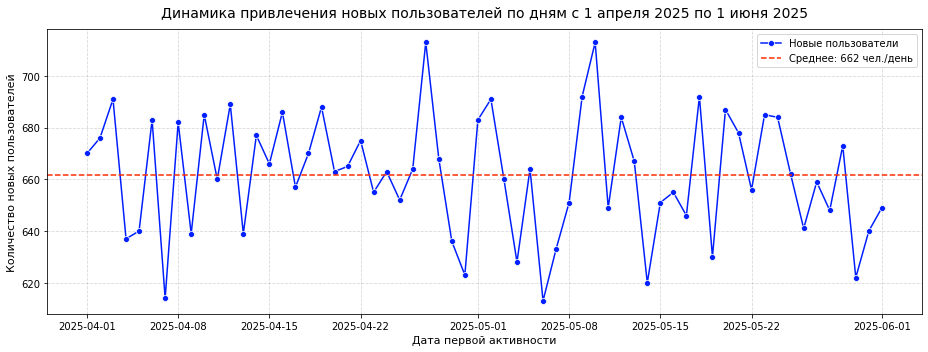

In [9]:
new_users_daily = df_hist.groupby('first_dt')['user_id'].nunique().reset_index()
mean_users = new_users_daily['user_id'].mean()

fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=new_users_daily, x='first_dt', y='user_id', marker='o', color='#001EFF', label='Новые пользователи', ax=ax)
ax.axhline(mean_users, color='#FF2B00', linestyle='--', linewidth=1.5, label=f'Среднее: {mean_users:.0f} чел./день')

ax.set_title('Динамика привлечения новых пользователей по дням с 1 апреля 2025 по 1 июня 2025', fontsize=14, pad=12)
ax.set_xlabel('Дата первой активности', fontsize=11)
ax.set_ylabel('Количество новых пользователей', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### Посмотрим также на динамику привлечения пользователей в разрезе стран:

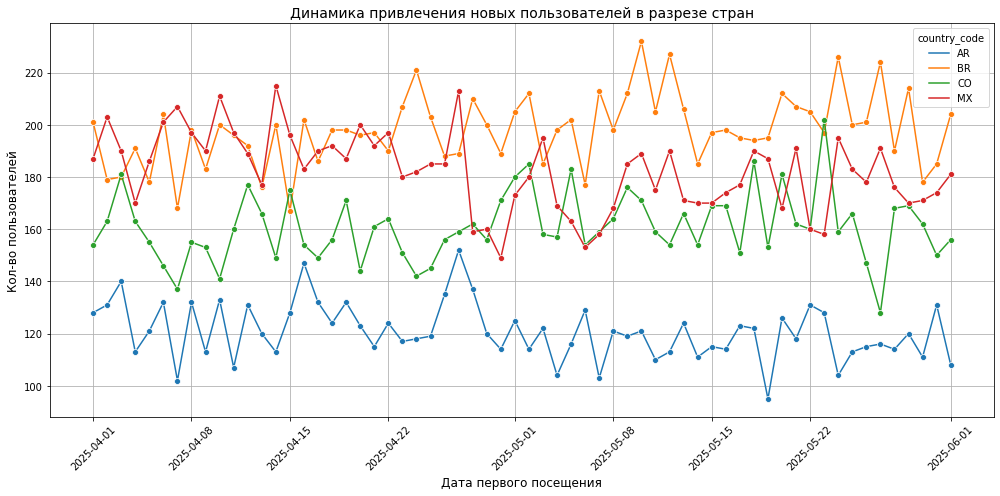

In [10]:
daily_country = df_hist.groupby(['first_dt', 'country_code'])['user_id'].nunique().reset_index()

plt.figure(figsize=(14, 7))
sns.lineplot(data=daily_country, x='first_dt', y='user_id', hue='country_code', marker='o')
plt.title('Динамика привлечения новых пользователей в разрезе стран', fontsize=14)
plt.xlabel('Дата первого посещения', fontsize=12)
plt.ylabel('Кол-во пользователей', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

##### Найдём, сколько в среднем привлекается новых пользователей в день по странам:

In [11]:
print(daily_country.groupby('country_code')['user_id'].mean().round(0))

country_code
AR    121.0
BR    198.0
CO    161.0
MX    182.0
Name: user_id, dtype: float64


##### А теперь посмотрим на динамику привлечения в разрезе платформ:

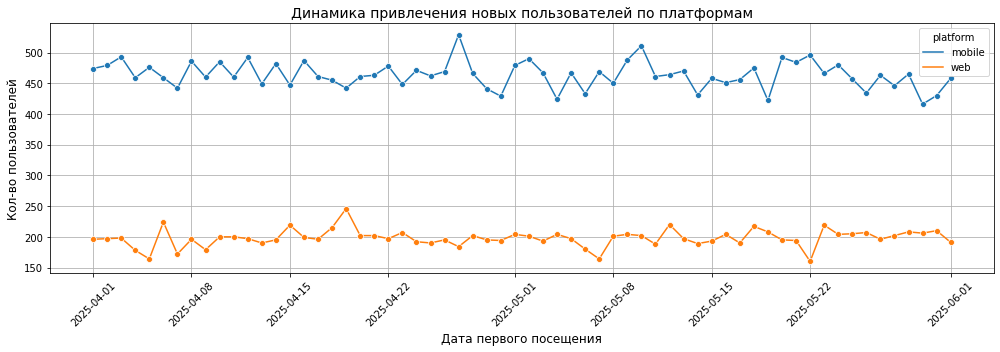

Среднее число пользователей в день по платформам:
platform
mobile    464.0
web       198.0
Name: user_id, dtype: float64


In [12]:
daily_platform = df_hist.groupby(['first_dt', 'platform'])['user_id'].nunique().reset_index()

plt.figure(figsize=(14, 5))
sns.lineplot(data=daily_platform, x='first_dt', y='user_id', hue='platform', marker='o')
plt.title('Динамика привлечения новых пользователей по платформам', fontsize=14)
plt.xlabel('Дата первого посещения', fontsize=12)
plt.ylabel('Кол-во пользователей', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

print("Среднее число пользователей в день по платформам:")
print(daily_platform.groupby('platform')['user_id'].mean().round(0))


**Промежуточный вывод:**
>Привлечение стабильное, без резких скачков или провалов. Средний показатель 662 человека в день, но есть колебания от 610 до 715. По странам больше всех пользователей привлекает Бразилия - в среднем 198 в день, за ней Мексика - 182, Колумбия - 161 и меньше всех Аргентина - 121. По платформам мобильные устройства сильно обгоняют web — 464 против 198 в день. Какого-то явного тренда нет, просто обычный шум в пределах нормы.

#### Анализ воронок событий.
- Построим классическую и пошаговую воронки;
- Охарактеризуем пользовательский путь в приложении и определим узкие места воронки. 


##### Расположим этапы воронки в хронологическом порядке, вычислим количество уникальных пользователей на каждом из этапов, рассчитаем классическую и пошаговую конверсии:

In [14]:
events_order = [
    'install / open_web', 'introduction', 'registration', 'main_page', 
    'onboarding_complete', 'first_deposit', 'asset_purchase', 'second_deposit'
]
funnel_all = df_hist.groupby('event_name')['user_id'].nunique().reindex(events_order).reset_index()
funnel_all.columns = ['event', 'users']
funnel_all['classic_cr_%'] = (funnel_all['users'] / funnel_all['users'].iloc[0] * 100).round(2)
funnel_all['step_cr_%'] = (funnel_all['users'] / funnel_all['users'].shift(1) * 100).round(2)
display(funnel_all)

,event,users,classic_cr_%,step_cr_%
0,install / open_web,41032,100.00,NaN
1,introduction,41032,100.00,100.00
2,registration,38133,92.93,92.93
3,main_page,35040,85.40,91.89
4,onboarding_complete,34337,83.68,97.99
5,first_deposit,27685,67.47,80.63
6,asset_purchase,15392,37.51,55.60
7,second_deposit,5408,13.18,35.14


##### Визуализируем классическую и пошаговую воронки:

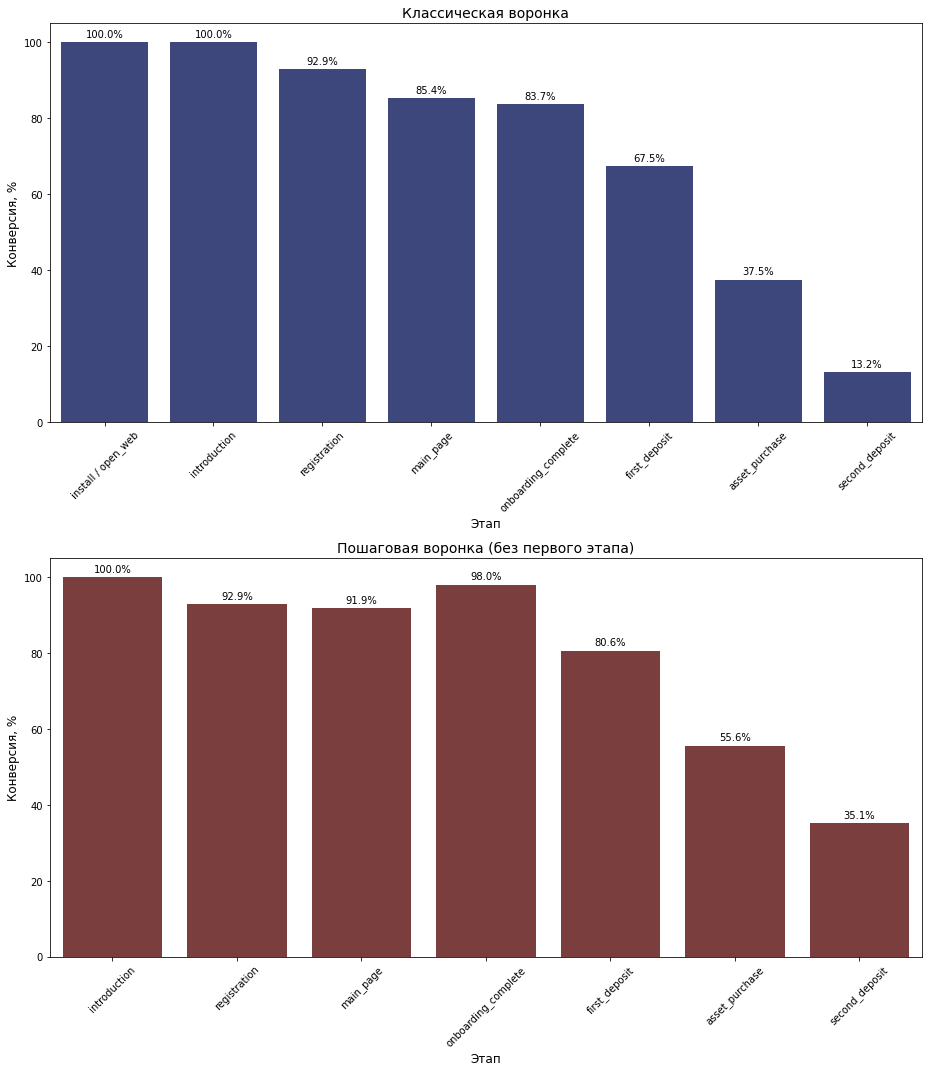

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(13, 15))

def add_labels(ax):
    for p in ax.patches:
        height = p.get_height()
        if pd.notna(height):
            ax.annotate(f'{height:.1f}%',
                        (p.get_x() + p.get_width() / 2, height),
                        ha='center', va='bottom',
                        xytext=(0, 3), textcoords='offset points')

ax1 = sns.barplot(x='event', y='classic_cr_%', data=funnel_all, ax=axes[0], color='#344085')
axes[0].set_title('Классическая воронка', fontsize=14)
axes[0].set_ylabel('Конверсия, %', fontsize=12)
axes[0].set_xlabel('Этап', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
add_labels(ax1)

step_by_step_df = funnel_all[funnel_all['event'] != 'install / open_web']
ax2 = sns.barplot(x='event', y='step_cr_%', data=step_by_step_df, ax=axes[1], color='#853434')
axes[1].set_title('Пошаговая воронка (без первого этапа)', fontsize=14)
axes[1].set_ylabel('Конверсия, %', fontsize=12)
axes[1].set_xlabel('Этап', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)
add_labels(ax2)

plt.tight_layout()
plt.show()

**Промежуточный вывод:** 
- Пользовательский путь начинается с установки или открытия веб-версии, затем идёт обучение, регистрация, главная страница и завершение онбординга. Их пользователи проходят достаточно уверенно. До первого депозита доходит около 67% от всех новых пользователей. После первого депозита происходит серьёзное падение - только 55% из тех, кто пополнил счёт, совершают покупку актива. И ещё более сильное снижение на втором депозите - лишь 35% от покупателей активов возвращаются на второй депозит.
- Главные узкие места - переход от онбординга к первому депозиту, где теряется около 20% пользователей, от первого депозита к покупке актива, где теряется около 45%, и от покупки к второму депозиту, где теряется около 65%. Это говорит о том, что многие пользователи доходят до пополнения, но не совершают инвестиций, а из тех, кто инвестирует, большинство не возвращается на второй депозит.

#### Влияние уровня риска актива на открытие второго депозита.
- Изучим, как уровень риска первого актива влияет на конверсию во второй депозит.  

##### Отбираем пользователей купивших первый актив и уровень риска этого актива:

In [16]:
asset_purchases = df_hist[df_hist['event_name'] == 'asset_purchase'][['user_id', 'risk_level']]
display(asset_purchases.head())

,user_id,risk_level
12,89923614-c303-414d-9788-b5ed77ccc740,medium
19,df7b9aae-7475-4878-a8c7-9bd3002fa226,high
26,f18e66dc-e9dd-4608-b067-716ec62f4e70,low
39,f1d9c60f-3365-4d6b-967a-099098b5efc9,high
51,56765f29-e127-402d-b45a-96427b6c37d2,high


##### Отбираем пользователей, которые совершили второй депозит:

In [17]:
users_with_second_deposit = df_hist[df_hist['event_name'] == 'second_deposit']['user_id'].unique()
asset_purchases['second_deposit'] = asset_purchases['user_id'].isin(users_with_second_deposit)
display(asset_purchases.head())

,user_id,risk_level,second_deposit
12,89923614-c303-414d-9788-b5ed77ccc740,medium,False
19,df7b9aae-7475-4878-a8c7-9bd3002fa226,high,False
26,f18e66dc-e9dd-4608-b067-716ec62f4e70,low,False
39,f1d9c60f-3365-4d6b-967a-099098b5efc9,high,False
51,56765f29-e127-402d-b45a-96427b6c37d2,high,True


##### Проведём группировку по уровню риска актива и вычислим количество человек в разрезе уровней риска и конверсию во второй депозит:

In [18]:
risk_conversion = asset_purchases.groupby('risk_level')['second_deposit'].agg(['count', 'sum', 'mean']).reset_index()
risk_conversion['mean'] = (risk_conversion['mean'] * 100).round(2)
risk_conversion.columns = ['Уровень риска', 'Купили актив (чел.)', 'Сделали второй депозит (чел.)', 'Конверсия во второй депозит, %']
display(risk_conversion.sort_values('Конверсия во второй депозит, %', ascending=False))

,Уровень риска,Купили актив (чел.),Сделали второй депозит (чел.),"Конверсия во второй депозит, %"
1,low,2327,1080,46.41
2,medium,5325,2288,42.97
0,high,7740,2040,26.36


##### Создаём палитру цветов для уровней риска:

In [19]:
risk_colors = {
    'low': '#87FF73',
    'medium': '#FFE173',
    'high': '#FF7373'
}

##### Визуализируем получившиеся данные для наглядного представления:

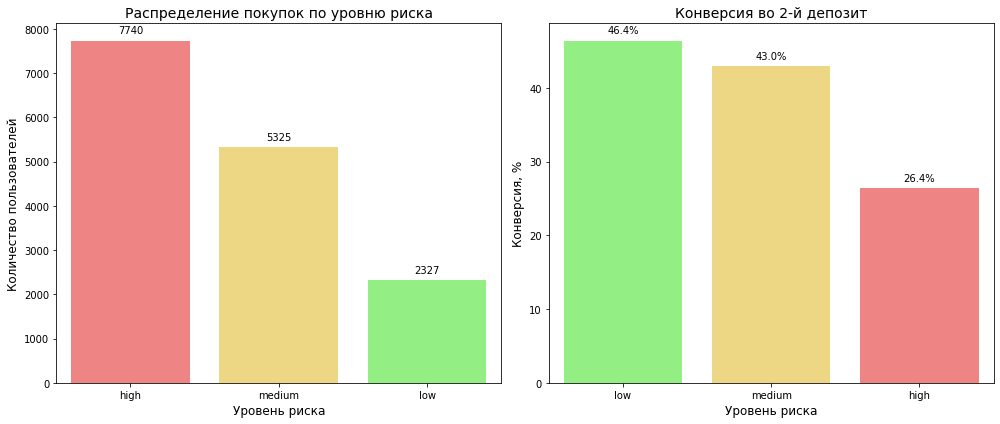

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

df_count_sorted = risk_conversion.sort_values('Купили актив (чел.)', ascending=False)
ax1 = sns.barplot(data=df_count_sorted, x='Уровень риска', y='Купили актив (чел.)', ax=axes[0], palette=risk_colors)
axes[0].set_title('Распределение покупок по уровню риска', fontsize=14)
axes[0].set_ylabel('Количество пользователей', fontsize=12)
axes[0].set_xlabel('Уровень риска', fontsize=12)

for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height())}', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')


df_conv_sorted = risk_conversion.sort_values('Конверсия во второй депозит, %', ascending=False)
ax2 = sns.barplot(data=df_conv_sorted, x='Уровень риска', y='Конверсия во второй депозит, %', ax=axes[1], palette=risk_colors)
axes[1].set_title('Конверсия во 2-й депозит', fontsize=14)
axes[1].set_ylabel('Конверсия, %', fontsize=12)
axes[1].set_xlabel('Уровень риска', fontsize=12)

for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.1f}%', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

**Промежуточный вывод:**

Анализ подтверждает, что уровень риска первого купленного актива напрямую влияет на возврат пользователя. Лучше всего конвертируются во второй депозит те, кто начал с низкого риска — 46,4%. Средний уровень даёт 43%. Хуже всего обстоят дела с высоким риском — всего 26,4% возвращаются на второй депозит.

Большинство пользователей (7740 человек) выбирают активы с высоким риском и идут на риск без понимания последствий. Это приводит к потере средств и оттоку. Меньшинство пользователей (2327 человек) выбирают низкий риск, но именно они чаще возвращаются.

На этом этапе и появляется гипотеза о недостаточной финансовой грамотности пользователей. Обучение в онбординге может помочь пользователям лучше понимать риски и повысить их удержание.

#### Анализ ключевой метрики на исторических данных.
- На исторических данных рассчитаем значение ключевой метрики — средней суммы всех депозитов на одного пользователя. Будем учитывать всех пользователей, которые взаимодействовали с сервисом. Это позволит зафиксировать базовый уровень монетизации.

##### Рассчитаем суммарные депозиты на каждого пользователя и найдем ARPU и ARPPU:

In [21]:
user_deposits_all = df_hist.groupby('user_id')['amount'].sum()
total_revenue = user_deposits_all.sum()
print(f"Общая выручка: {total_revenue}")

Общая выручка: 3756981.0


##### Рассчитаем метрики ARPU и ARPPU и выведем сводную статистику:

In [22]:
total_users = len(user_deposits_all)
paying_users = (user_deposits_all > 0).sum()
non_paying_users = (user_deposits_all == 0).sum()

arpu = user_deposits_all.mean()
median_all = user_deposits_all.median()

paying_deposits = user_deposits_all[user_deposits_all > 0]
arppu = paying_deposits.mean()
median_paying = paying_deposits.median()

print(f"Всего пользователей: {total_users}")
print(f"Неплатящих пользователей: {non_paying_users} ({non_paying_users / total_users * 100:.2f}%)")
print(f"Платящих пользователей: {paying_users} ({paying_users / total_users * 100:.2f}%)")
print(f"Общая выручка от депозитов: {total_revenue}")
print(f"ARPU: {arpu:.2f}")
print(f"Медианная сумма депозитов: {median_all:.2f}")
print(f"ARPPU: {arppu:.2f}")
print(f"Медианный депозит на платящего: {median_paying:.2f}")

Всего пользователей: 41032
Неплатящих пользователей: 13347 (32.53%)
Платящих пользователей: 27685 (67.47%)
Общая выручка от депозитов: 3756981.0
ARPU: 91.56
Медианная сумма депозитов: 96.00
ARPPU: 135.70
Медианный депозит на платящего: 118.00


##### Построим визуализацию распределения депозитов на платящего пользователя:

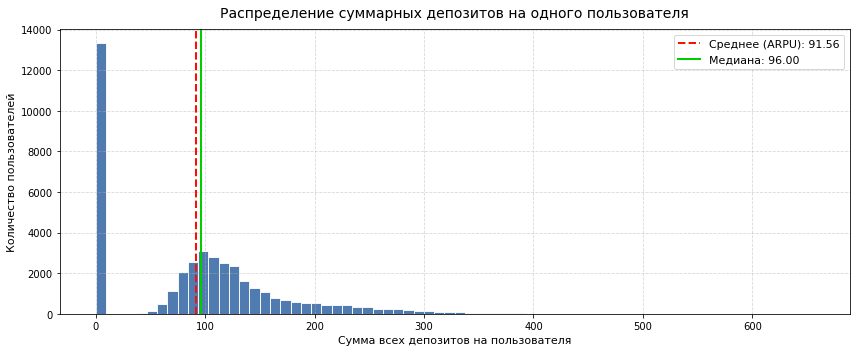

In [23]:
plt.figure(figsize=(12, 5))
ax = sns.histplot(user_deposits_all, bins=70, color='#3164A3', edgecolor='white', alpha=0.85)

plt.axvline(arpu, color='#FF0D00', linestyle='--', linewidth=2, label=f'Среднее (ARPU): {arpu:.2f}')
plt.axvline(median_all, color='#00CC00', linestyle='-', linewidth=2, label=f'Медиана: {median_all:.2f}')

plt.title('Распределение суммарных депозитов на одного пользователя', fontsize=14, pad=12)
plt.xlabel('Сумма всех депозитов на пользователя', fontsize=11)
plt.ylabel('Количество пользователей', fontsize=11)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Промежуточный вывод:**
- ARPU составил 91,56. При этом 67,47% новых пользователей совершили хотя бы один депозит, а 32,53% - не вносили средства вовсе. 
- Медиана по всей аудитории - 96, что ниже среднего из-за большого количества нулевых депозитов. На графике распределения они формируют доминирующий нулевой пик. Треть пользователей вообще не доходит до первого пополнения, и это главная точка роста - даже небольшое улучшение конверсии в первый депозит даст значительный прирост выручки без изменения среднего чека.
- Среди платящих ARPPU равен 135,7, медиана - 118. Разница между средней и медианой объясняется небольшой долей крупных депозитов, формирующих длинный правый хвост. Основная масса платящих вносит суммы в районе 100, что подтверждает пик гистограммы.

---

## Часть 2

### Исследование результатов А/В эксперимента
Загрузим данные с результатами эксперимента (датасет `pa_sollmafin_abt.csv `). Проверим корректность данных, проведём предобработку.
Затем проведем анализ результатов А/В-эксперимента.

##### Загружаем данные A/B теста и посмотрим основную информацию о них:

In [24]:
df_ab = pd.read_csv('***', parse_dates=['first_ts', 'first_dt', 'event_ts'])
df_ab.info()
print(f"\nВсего записей {len(df_ab)}, уникальных пользователей {df_ab['user_id'].nunique()}")
print(f"Период регистрации с {df_ab['first_dt'].min().date()} по {df_ab['first_dt'].max().date()}")
print(f"Период событий с {df_ab['event_ts'].min()} по {df_ab['event_ts'].max()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54805 entries, 0 to 54804
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   user_id       54805 non-null  object        
 1   country_code  54805 non-null  object        
 2   platform      54805 non-null  object        
 3   first_ts      54805 non-null  datetime64[ns]
 4   first_dt      54805 non-null  datetime64[ns]
 5   event_ts      54805 non-null  datetime64[ns]
 6   event_name    54805 non-null  object        
 7   ab_test       54805 non-null  object        
 8   group         54805 non-null  object        
 9   amount        7843 non-null   float64       
 10  asset         3750 non-null   object        
 11  risk_level    3750 non-null   object        
dtypes: datetime64[ns](3), float64(1), object(8)
memory usage: 5.0+ MB

Всего записей 54805, уникальных пользователей 9415
Период регистрации с 2025-06-02 по 2025-06-15
Период событий с 2025-

##### Проверим датасет на пропуски также, как мы делали это с историческими данными до этого:

In [25]:
print(f'Пропуски в датасете:\n{df_ab.isnull().sum()}')
#Посмотрим, где пропуски, а где заполненные строки и сколько
print("\nКоличество заполненных строк в столбцах с пропусками:")
display(df_ab.groupby('event_name')[['amount', 'asset', 'risk_level']].count())

Пропуски в датасете:
user_id             0
country_code        0
platform            0
first_ts            0
first_dt            0
event_ts            0
event_name          0
ab_test             0
group               0
amount          46962
asset           51055
risk_level      51055
dtype: int64

Количество заполненных строк в столбцах с пропусками:


,amount,asset,risk_level
event_name,,,
asset_purchase,0,3750,3750
first_deposit,6215,0,0
install / open_web,0,0,0
introduction,0,0,0
main_page,0,0,0
onboarding_complete,0,0,0
registration,0,0,0
second_deposit,1628,0,0


##### Проверим, один ли тест у нас в данных, есть ли помимо тестовой и контрольной другие группы, записанные события:

In [26]:
print(f"Название эксперимента: {df_ab['ab_test'].unique().tolist()}")
print(f"Группы теста: {df_ab['group'].unique().tolist()}")
print(f"События: {df_ab['event_name'].unique().tolist()}")

Название эксперимента: ['onboarding_test']
Группы теста: ['test', 'control']
События: ['install / open_web', 'introduction', 'registration', 'main_page', 'onboarding_complete', 'first_deposit', 'asset_purchase', 'second_deposit']


##### Проверим датасет на явные и неявные дубликаты (по пользователю и событию):

In [27]:
print(f"\nКоличество явных дубликатов: {df_ab.duplicated().sum()}")
print(f"Дубликаты по пользователю и событию: {df_ab.duplicated(subset=['user_id', 'event_name']).sum()}")


Количество явных дубликатов: 0
Дубликаты по пользователю и событию: 0


**Вывод:**
- Данные A/B-теста загружены и проверены. В датасете 54 805 строк и 9 415 уникальных пользователей, период регистрации — со 2 по 15 июня, события — до 22 июня. Пропуски в amount, asset, risk_level ожидаемы и заполнены только для событий депозитов и покупок активов. В данных один эксперимент onboarding_test и две группы - test, control, дубликатов по пользователю и событию нет. Структура событий совпадает с историческими данными, поэтому можно переходить к анализу.

#### Анализ аудитории эксперимента. 
- Проверим корректность распределения новых пользователей по группам А/В-эксперимента. 
- Построим графики. 

##### Проверим распределение пользователей по группам:

In [28]:
users_per_group = df_ab.groupby('group')['user_id'].nunique().reset_index()
users_per_group.columns = ['Группа', 'Пользователей']
users_per_group['Доля, %'] = (users_per_group['Пользователей']/ users_per_group['Пользователей'].sum()* 100).round(2)
display(users_per_group)

,Группа,Пользователей,"Доля, %"
0,control,4847,51.48
1,test,4568,48.52


##### Проверим, есть ли пользователи, которые смогли попасть сразу в обе группы:

In [29]:
users_groups_count = df_ab.groupby('user_id')['group'].nunique()
crossed_users = users_groups_count[users_groups_count > 1].count()
print(f"Количество пользователей, попавших в обе группы: {crossed_users}")

Количество пользователей, попавших в обе группы: 0


##### Подготовим датасет только с уникальными юзерами для проверки платформ и стран. Нам нужно на каждого пользователя оставить только одно событие:

In [30]:
users_unique = df_ab.drop_duplicates(subset=['user_id'])
users_unique.head()

,user_id,country_code,platform,first_ts,first_dt,event_ts,event_name,ab_test,group,amount,asset,risk_level
0,c430acb5-c6bf-43cf-8e2d-7ab9ce0d2c8a,BR,mobile,2025-06-07 19:55:51,2025-06-07,2025-06-07 19:55:51,install / open_web,onboarding_test,test,NaN,NaN,NaN
7,03032063-0f54-444f-a25a-f36448c8b16b,MX,mobile,2025-06-06 12:35:02,2025-06-06,2025-06-06 12:35:02,install / open_web,onboarding_test,test,NaN,NaN,NaN
14,f61feefc-576b-4d03-ad70-7ccee1de479c,CO,web,2025-06-03 09:51:31,2025-06-03,2025-06-03 09:51:31,install / open_web,onboarding_test,test,NaN,NaN,NaN
18,a2cd4929-9141-496e-81a5-da4958cc8f69,CO,mobile,2025-06-05 11:19:58,2025-06-05,2025-06-05 11:19:58,install / open_web,onboarding_test,test,NaN,NaN,NaN
20,db37d8ea-902a-41ea-a0b4-b355167c8f74,BR,web,2025-06-09 21:42:24,2025-06-09,2025-06-09 21:42:24,install / open_web,onboarding_test,control,NaN,NaN,NaN


##### Подготовим дневную и кумулятивную динамику:

In [31]:
daily_users = df_ab.groupby(['first_dt', 'group'])['user_id'].nunique().reset_index()
daily_users['cum_users'] = daily_users.groupby('group')['user_id'].cumsum()

##### Построим графики: 
    - Динамика привлечения пользователей по дням
    - Накопительное количество пользователей
    - Распределение пользователей по платформам
    - Распределение пользователей по странам
Так мы полностью сможем убедиться в корректности распределения пользователей по группам.

In [32]:
#Присвоим цветам группам:
group_colors = {
    'control': '#2750F5',
    'test': '#F53527'
}

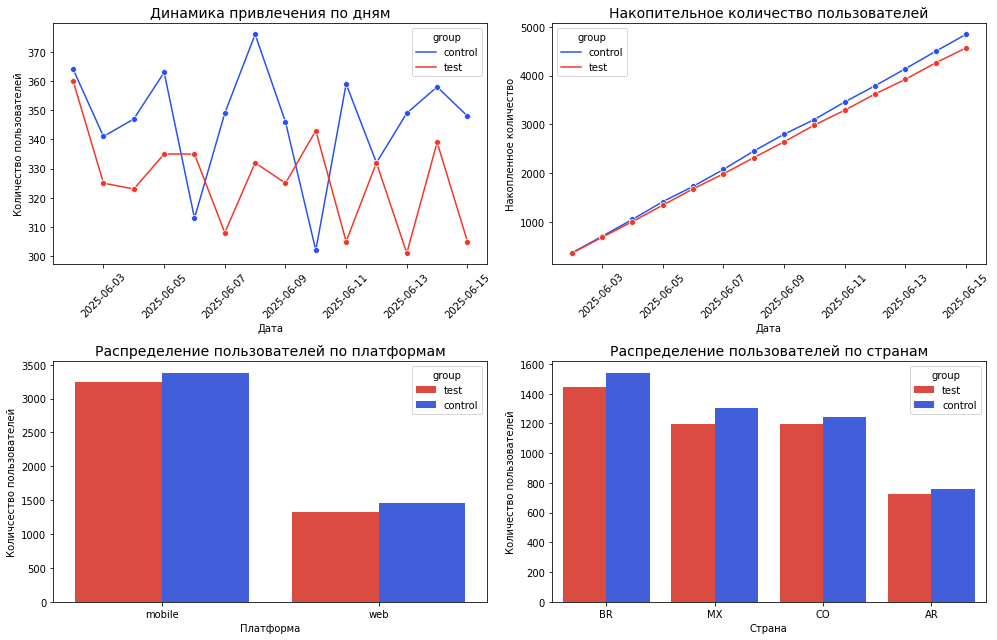

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.lineplot(data=daily_users, x='first_dt', y='user_id', hue='group', marker='o', palette=group_colors, ax=axes[0, 0])
axes[0, 0].set_title('Динамика привлечения по дням', fontsize=14)
axes[0, 0].set_ylabel('Количество пользователей')
axes[0, 0].set_xlabel('Дата')
axes[0, 0].tick_params(axis='x', rotation=45)

sns.lineplot(data=daily_users, x='first_dt', y='cum_users', hue='group', marker='o', palette=group_colors, ax=axes[0, 1])
axes[0, 1].set_title('Накопительное количество пользователей', fontsize=14)
axes[0, 1].set_ylabel('Накопленное количество')
axes[0, 1].set_xlabel('Дата')
axes[0, 1].tick_params(axis='x', rotation=45)

sns.countplot(data=users_unique, x='platform', hue='group', palette=group_colors, ax=axes[1, 0])
axes[1, 0].set_title('Распределение пользователей по платформам', fontsize=14)
axes[1, 0].set_ylabel('Количсество пользователей')
axes[1, 0].set_xlabel('Платформа')

sns.countplot(data=users_unique, x='country_code', hue='group', palette=group_colors, order=['BR', 'MX', 'CO', 'AR'], ax=axes[1, 1])
axes[1, 1].set_title('Распределение пользователей по странам', fontsize=14)
axes[1, 1].set_ylabel('Количество пользователей')
axes[1, 1].set_xlabel('Страна')

plt.tight_layout()
plt.show()

**Промежуточный вывод:**
- Распределение пользователей по группам - 51,5% в контрольной, 48,5% в тестовой, разница небольшая. Пользователей попавших в обе группы нет.

- Динамика привлечения по дням и накопительная кривая показывают, что приток пользователей в обе группы шёл параллельно без скачков в одну из сторон. Распределение по платформам и странам также почти одинаковое - различия минимальны и не дают перевеса ни одной группе.


***Группы сформированы случайно и однородно.***

#### Сравнение воронок событий.
- Сравним пользовательский путь новых пользователей в тестовой и контрольной группах.
- Построим классическую и последовательную воронки, сделаем визуализацию. 

##### Соберём данные для воронок и рассчитаем конверсию:

In [34]:
funnel_ab = (
    df_ab.groupby(['group', 'event_name'])['user_id']
    .nunique()
    .reindex(
        pd.MultiIndex.from_product(
            [['control', 'test'], events_order],
            names=['group', 'event_name']
        ),
        fill_value=0
    )
    .reset_index(name='users')
)
funnel_ab['classic'] = (funnel_ab['users']/ funnel_ab.groupby('group')['users'].transform('first') * 100).round(2)
funnel_ab['step_by_step'] = (funnel_ab['users'] / funnel_ab.groupby('group')['users'].shift(1) * 100).round(2)

##### Поменяем названия групп на русские:

In [35]:
group_labels = {
    'control': 'Контрольная',
    'test': 'Тестовая'
}

##### Построим классическую и пошаговую воронки на контрольной и тестовой групп и сравним их:

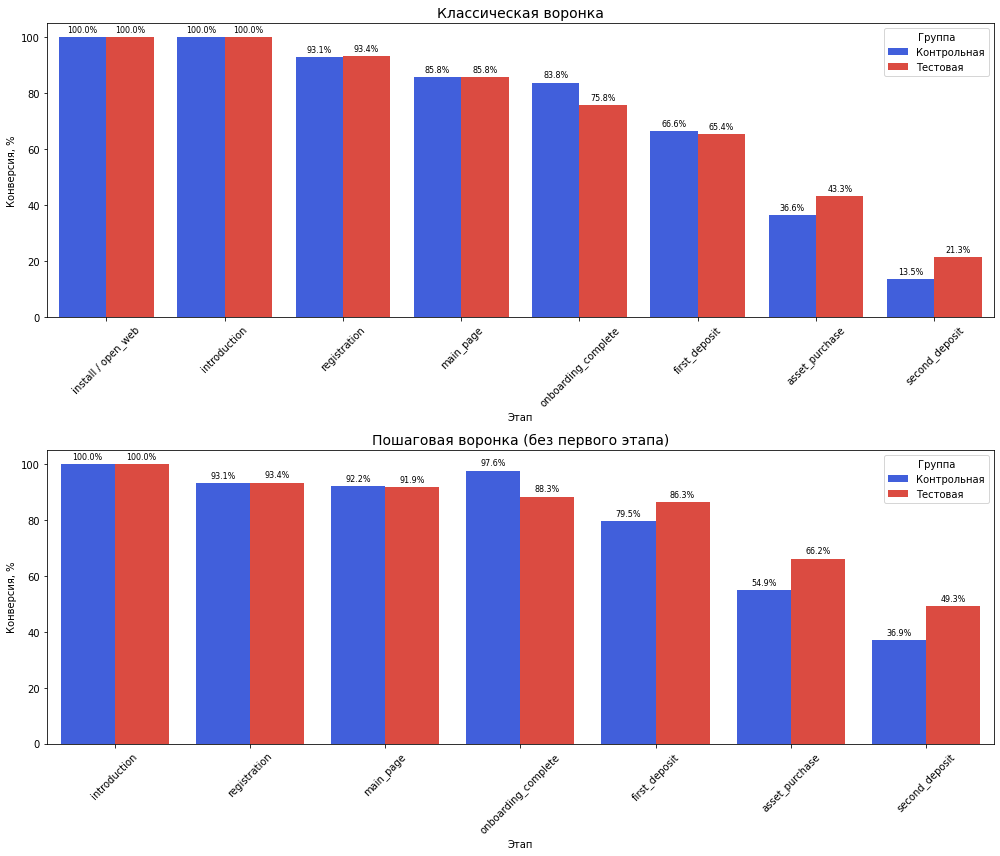

In [36]:
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

def add_labels(ax):
    for bar in ax.patches:
        height = bar.get_height()

        if pd.notna(height) and height > 0:
            ax.annotate(
                f'{height:.1f}%',
                (bar.get_x() + bar.get_width() / 2, height),
                ha='center',
                va='bottom',
                xytext=(0, 3),
                textcoords='offset points',
                fontsize=8
            )

ax1 = sns.barplot(
    x='event_name', 
    y='classic', 
    hue='group', 
    data=funnel_ab, 
    ax=axes[0], 
    palette=group_colors
)
axes[0].set_title('Классическая воронка', fontsize=14)
axes[0].set_xlabel('Этап')
axes[0].set_ylabel('Конверсия, %')
axes[0].tick_params(axis='x', rotation=45)

handles, labels = ax1.get_legend_handles_labels()
axes[0].legend(
    handles=handles,
    labels=[group_labels[label] for label in labels],
    title='Группа'
)

add_labels(ax1)

step_by_step_ab = funnel_ab[funnel_ab['event_name'] != 'install / open_web']
ax2 = sns.barplot(
    x='event_name', 
    y='step_by_step', 
    hue='group', 
    data=step_by_step_ab, 
    ax=axes[1], 
    palette=group_colors
)
axes[1].set_title('Пошаговая воронка (без первого этапа)', fontsize=14)
axes[1].set_xlabel('Этап')
axes[1].set_ylabel('Конверсия, %')
axes[1].tick_params(axis='x', rotation=45)

handles, labels = ax2.get_legend_handles_labels()
axes[1].legend(
    handles=handles,
    labels=[group_labels[label] for label in labels],
    title='Группа'
)

add_labels(ax2)

plt.tight_layout()
plt.show()

**Промежуточный вывод:**

- В начале пути пользователи из обеих групп ведут себя практически одинаково.
Но когда доходит до обучения тестовая группа теряет больше людей - они проходят онбординг хуже (в классической воронке 75,8% против 83,8%). Новый онбординг длиннее, не все доходят до конца.
- А вот дальше, у тех кто всё-таки прошёл обучение, результаты становятся лучше. Конверсия в первый депозит в пошаговой воронке у теста 86,3%, а у контроля 79,5%. Далее разница между группами становится еще заметнее. Покупка актива - 66,2% против 54,9%, а второй депозит - 49,3% против 36,9% в пользу тестовой группы.

- То есть обучение действительно помогает, людям, которые его прошли, проще решиться на вложение, и они чаще возвращаются. Получается, что объяснение рисков не отпугивает, а наоборот - повышает уверенность и повторные действия.

#### Влияние новой фичи на конверсию во второй депозит с учётом уровня риска купленного актива.
- Проанализируем, как категория риска купленного актива влияет на вероятность открытия второго депозита в тестовой и контрольной группах. 
- Сравним результаты и оценим, есть ли статистически значимая разница между группами. 

##### Отбираем пользователей с покупкой актива и проверяем наличие 2-го депозита:

In [37]:
asset_users = df_ab[df_ab['event_name'] == 'asset_purchase'][['user_id', 'group', 'risk_level']].copy()
second_dep_users = set(df_ab[df_ab['event_name'] == 'second_deposit']['user_id'])
asset_users['second_deposit'] = asset_users['user_id'].isin(second_dep_users)

##### Проводим агрегацию по уровню риска и группе:

In [38]:
risk_order = ['low', 'medium', 'high']
risk_ab = (
    asset_users.groupby(['risk_level', 'group'])['second_deposit']
    .agg(total='count', converted='sum', conversion='mean')
    .reindex(pd.MultiIndex.from_product([risk_order, ['control', 'test']], names=['risk_level', 'group']))
    .reset_index()
)

risk_ab['conversion_%'] = (risk_ab['conversion'] * 100).round(2)
risk_ab['share_in_group_%'] = (risk_ab['total'] / risk_ab.groupby('group')['total'].transform('sum') * 100).round(2)

##### Далее нам необходим z-тест пропорций для того, чтобы оценить, есть ли статистическая разница между группами:

In [39]:
statistical_results = []

for r in risk_order:
    c_sub = risk_ab[(risk_ab['risk_level'] == r) & (risk_ab['group'] == 'control')].iloc[0]
    t_sub = risk_ab[(risk_ab['risk_level'] == r) & (risk_ab['group'] == 'test')].iloc[0]
    
    stat, p_val = proportions_ztest(
        count=[t_sub['converted'], c_sub['converted']],
        nobs=[t_sub['total'], c_sub['total']]
    )
    
    statistical_results.append({
        'Уровень риска': r,
        'control: купили (чел.)': int(c_sub['total']),
        'control: конверсия во 2-й депозит (%)': c_sub['conversion_%'],
        'test: купили (чел.)': int(t_sub['total']),
        'test: конверсия во 2-й депозит (%)': t_sub['conversion_%'],
        'Статистически значимо a=0.05': 'Да' if p_val < 0.05 else 'Нет'
    })

stat_df = pd.DataFrame(statistical_results)
display(stat_df)

,Уровень риска,control: купили (чел.),control: конверсия во 2-й депозит (%),test: купили (чел.),test: конверсия во 2-й депозит (%),Статистически значимо a=0.05
0,low,285,49.82,496,57.46,Да
1,medium,595,44.54,744,47.04,Нет
2,high,893,27.66,737,46.00,Да


##### Построим визуализацию:

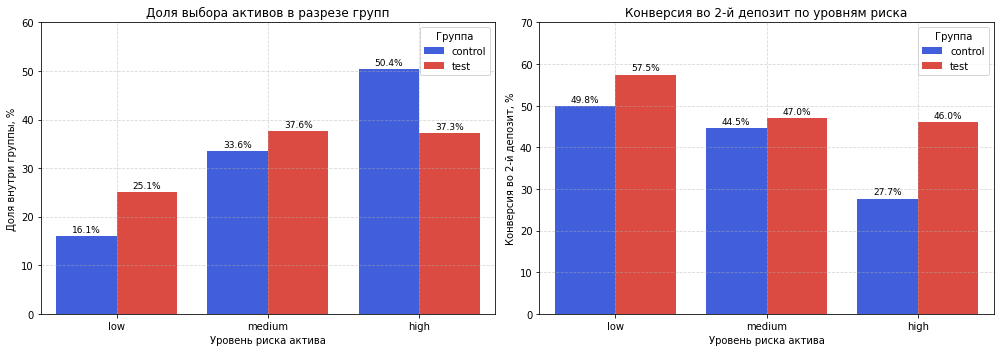

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = sns.barplot(data=risk_ab, x='risk_level', y='share_in_group_%', hue='group', palette=group_colors, ax=axes[0])
axes[0].set_title('Доля выбора активов в разрезе групп', fontsize=12)
axes[0].set_xlabel('Уровень риска актива')
axes[0].set_ylabel('Доля внутри группы, %')
axes[0].set_ylim(0, 60)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(title='Группа')

for p in ax1.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        ax1.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', xytext=(0, 2), textcoords='offset points', fontsize=9)

ax2 = sns.barplot(data=risk_ab, x='risk_level', y='conversion_%', hue='group', palette=group_colors, ax=axes[1])
axes[1].set_title('Конверсия во 2-й депозит по уровням риска', fontsize=12)
axes[1].set_xlabel('Уровень риска актива')
axes[1].set_ylabel('Конверсия во 2-й депозит, %')
axes[1].set_ylim(0, 70)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(title='Группа')

for p in ax2.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        ax2.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', xytext=(0, 2), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()

**Промежуточный вывод:** 

- В тестовой группе доля низкорисковых выросла до 25,1% (против 16,1% в контроле), а высокорисковых упала до 37,3% (против 50,4%). При этом конверсия во второй депозит статистически значимо выросла у тех, кто взял низкий риск (57,5% против 49,8%) и высокий риск (46% против 27,7%). 
- По среднему риску разницы нет — там все примерно одинаково. 
- Получается, что обучение действительно работает. Оно смещает людей в сторону безопасных активов и повышает удержание среди тех, кто выбирает как низкий, так и высокий риск, хотя в среднем риске эффекта не видно.

#### Анализ метрик А/В-эксперимента.
- Ключевая метрика — средняя сумма всех депозитов на одного пользователя (включая тех, кто установил приложение или открыл веб-версию).
- Барьерная метрика — конверсия из регистрации в первый депозит.
- Вспомогательная метрика 1 — конверсия из первого депозита во второй.
- Вспомогательная метрика 2 — средняя сумма всех депозитов на пользователя, который открыл хотя бы один депозит.

Для каждой метрики выведем: 
- значения в контрольной и тестовой группах, 
- абсолютные и относительные изменения значений в тестовой группе по сравнению с контрольной.

После этого проверим статистическую значимость различий метрик между группами эксперимента. 

Для ключевой метрики также изучим:
- накопленную динамику изменения по дням эксперимента для каждой группы, 
- стабильность p-value во время эксперимента.

##### Нам нужно рассчитать количество уникальных пользователей на этапах регистрации, первого депозита и второго депозита, а затем провести z-тесты для барьерной и вспомогательной метрик.

In [41]:
users_reg = df_ab[df_ab['event_name'] == 'registration'].groupby('group')['user_id'].nunique()
users_dep1 = df_ab[df_ab['event_name'] == 'first_deposit'].groupby('group')['user_id'].nunique()
users_dep2 = df_ab[df_ab['event_name'] == 'second_deposit'].groupby('group')['user_id'].nunique()

#Барьерная метрика
z_stat_bar, pval_bar = proportions_ztest(
    [users_dep1['control'], users_dep1['test']], 
    [users_reg['control'], users_reg['test']]
)

#Вспомогательная метрика 1
z_stat_aux1, pval_aux1 = proportions_ztest(
    [users_dep2['control'], users_dep2['test']], 
    [users_dep1['control'], users_dep1['test']]
)

##### Считаем выручку на платящих и на всех пользователей. Затем проведём t-тесты:

In [42]:
#Выручка на платящих
rev_paying = df_ab.dropna(subset=['amount']).groupby(['user_id', 'group'])['amount'].sum().reset_index()

#Выручка на всех
rev_all = df_ab[['user_id', 'group', 'first_dt']].drop_duplicates()
rev_all = rev_all.merge(rev_paying[['user_id', 'amount']], on='user_id', how='left').fillna(0)

#Разделение на группы
arpu_c, arpu_t = rev_all[rev_all['group'] == 'control']['amount'], rev_all[rev_all['group'] == 'test']['amount']
arppu_c, arppu_t = rev_paying[rev_paying['group'] == 'control']['amount'], rev_paying[rev_paying['group'] == 'test']['amount']

#t-тесты
tstat_arpu, pval_arpu = ttest_ind(arpu_c, arpu_t, equal_var=False)
tstat_arppu, pval_arppu = ttest_ind(arppu_c, arppu_t, equal_var=False)

##### Собираем все метрики в одну таблицу, добавляем абсолютную и относительную разницу, а также указываем, есть ли статистическая значимость:

In [43]:
metrics_df = pd.DataFrame({
    'Метрика': [
        'Барьерная метрика, %', 
        'Вспомогательная метрика 1, %', 
        'Ключевая метрика', 
        'Вспомогательная метрика 2'
    ],
    'Контрольная': [
        (users_dep1['control'] / users_reg['control']) * 100,
        (users_dep2['control'] / users_dep1['control']) * 100,
        arpu_c.mean(), arppu_c.mean()
    ],
    'Тестовая': [
        (users_dep1['test'] / users_reg['test']) * 100,
        (users_dep2['test'] / users_dep1['test']) * 100,
        arpu_t.mean(), arppu_t.mean()
    ],
    'P-value': [pval_bar, pval_aux1, pval_arpu, pval_arppu]
})
#Добавляем расчёты разницы
metrics_df['Абсолютная разница'] = metrics_df['Тестовая'] - metrics_df['Контрольная']
metrics_df['Относительная разница, %'] = (metrics_df['Тестовая'] / metrics_df['Контрольная'] - 1) * 100
metrics_df['Статистически значимо'] = metrics_df['P-value'].apply(lambda x: 'Да' if x < 0.05 else 'Нет')
display(metrics_df.round(3))

,Метрика,Контрольная,Тестовая,P-value,Абсолютная разница,"Относительная разница, %",Статистически значимо
0,"Барьерная метрика, %",71.543,70.035,0.121,-1.507,-2.107,Нет
1,"Вспомогательная метрика 1, %",20.260,32.608,0.000,12.348,60.946,Да
2,Ключевая метрика,90.240,92.461,0.338,2.221,2.461,Нет
3,Вспомогательная метрика 2,135.500,141.400,0.040,5.900,4.354,Да


---
##### Создадим отдельный столбец с датой события:

In [44]:
df_ab['event_dt'] = df_ab['event_ts'].dt.date
dates = sorted(df_ab['first_dt'].dt.date.unique())

##### Создадим три пустых списка, в них будем записывать накопленные значения ARPU и p-value, чтоб потом по ним построить график:

In [45]:
cum_arpu_c = [] #накопленный ARPU контроля
cum_arpu_t = [] #накопленный ARPU теста
cum_pvals = [] #динамика p-value

##### Теперь нам нужно заполнить созданные списки значениями для визуализации. Для этого запустим цикл:

In [46]:
for d in dates:
    cohort_users = df_ab[df_ab['first_dt'].dt.date <= d][['user_id', 'group']].drop_duplicates()
    cohort_deposits = df_ab[
        (df_ab['event_dt'] <= d) & 
        (df_ab['event_name'].isin(['first_deposit', 'second_deposit']))
    ]
    cohort_revenue = cohort_deposits.groupby('user_id')['amount'].sum().reset_index()
    
    #соединим всех пользователей когорты с их выручкой на текущий день
    cum_data = cohort_users.merge(cohort_revenue, on='user_id', how='left').fillna({'amount': 0})
    
    #разделим на группы
    c_dat = cum_data[cum_data['group'] == 'control']['amount']
    t_dat = cum_data[cum_data['group'] == 'test']['amount']
    
    #считаем ARPU
    cum_arpu_c.append(c_dat.mean())
    cum_arpu_t.append(t_dat.mean())
    
    #считаем p-value
    cum_pvals.append(ttest_ind(c_dat, t_dat, equal_var=False)[1])

##### Визуализируем полученные данные:

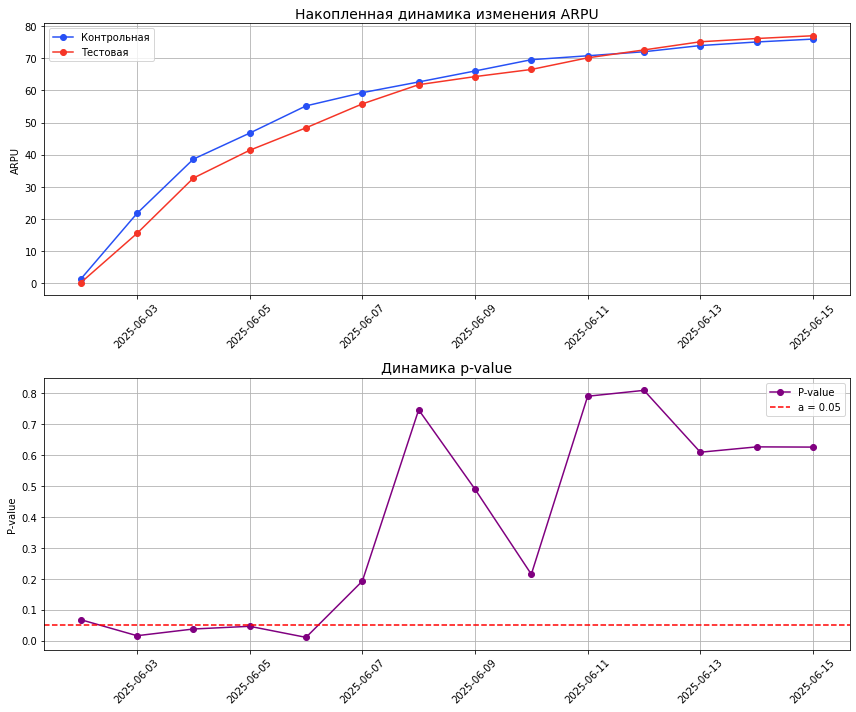

In [47]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].plot(dates, cum_arpu_c, marker='o', color=group_colors['control'], label=group_labels['control'])
axes[0].plot(dates, cum_arpu_t, marker='o', color=group_colors['test'], label=group_labels['test'])
axes[0].set_title('Накопленная динамика изменения ARPU', fontsize=14)
axes[0].set_ylabel('ARPU')
axes[0].legend()
axes[0].grid(True, alpha=1)

axes[1].plot(dates, cum_pvals, marker='o', color='purple', label='P-value')
axes[1].axhline(y=0.05, color='red', linestyle='--', label='a = 0.05')
axes[1].set_title('Динамика p-value', fontsize=14)
axes[1].set_ylabel('P-value')
axes[1].legend()
axes[1].grid(True, alpha=1)

for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Промежуточный вывод:**

- Ключевая метрика ARPU не изменилась статистически значимо (92,46 против 90,24, p=0,338). На графике видно, что тест сначала отстаёт от контроля, потом выравнивается к середине и к концу эксперимента слегка выходит вперёд, но эти колебания слишком мелкие. Барьерная метрика - конверсия в первый депозит - тоже осталась без изменений (70,0% против 71,5%, p=0,121). То есть новый онбординг не отпугивает новичков от первого пополнения, но и не помогает им быстрее решиться.
- Вспомогательные метрики показали значимый рост. Конверсия из первого депозита во второй выросла с 20,3% до 32,6% (p<0,001), а средний чек у платящих увеличился с 135,5 до 141,4 (p=0,040). Получается, что обучение реально улучшает удержание и вовлечённость тех, кто уже внес деньги.
- Динамика p-value очень нестабильная. В первые три-четыре дня он падает ниже 0,05, когда тестовая группа по ARPU была хуже контроля. Потом p-value резко подскакивает до 0,75 и до конца эксперимента так и держится выше порога. Ранняя значимость в начале - это просто шум на маленьких выборках, итогового эффекта по ключевой метрике нет.

---
### Анализ изменений суммы депозитов на платящего пользователя

Новая фича могла повлиять на поведение пользователей.
- Пользователи, которые раньше вносили небольшие суммы, могли стать более осторожными, сократить свои вложения или совсем перестать платить. Это отразится в снижении 25-го перцентиля суммы депозитов в тестовой группе.
- Пользователи, которые склонны к более крупным инвестициям, могли сильнее вовлечься в продукт и начать вносить больше средств. Это отразится в росте 75-го перцентиля.

С помощью бутстрапа, сравним разницы перцентилей суммы всех депозитов на платящего пользователя в контрольной и тестовой группах:
- Построим доверительные интервалы для разницы между группами для каждого перцентиля.
- Интерпретируем изменения в контексте сформулированной выше гипотезы.
- Визуализируем результат бутстрап-теста.

##### Сформируем выборки сумм депозитов на платящего пользователя:

In [48]:
control_amounts = rev_paying[rev_paying['group'] == 'control']['amount'].values
test_amounts = rev_paying[rev_paying['group'] == 'test']['amount'].values

##### Вычислим перцентили распределения сумм депозитов для контрольной и тестовой групп с помощью библиотеки Numpy:

In [49]:
p25_c, p50_c, p75_c = np.percentile(control_amounts, [25, 50, 75])
p25_t, p50_t, p75_t = np.percentile(test_amounts, [25, 50, 75])

#####  Проведём бутстрап анализ:

In [50]:
np.random.seed(341)
n_iterations = 1000
boot_diffs_25, boot_diffs_50, boot_diffs_75 = [], [], []

for _ in range(n_iterations):
    boot_c = np.random.choice(control_amounts, size=len(control_amounts), replace=True)
    boot_t = np.random.choice(test_amounts, size=len(test_amounts), replace=True)
    
    boot_diffs_25.append(np.percentile(boot_t, 25) - np.percentile(boot_c, 25))
    boot_diffs_50.append(np.percentile(boot_t, 50) - np.percentile(boot_c, 50))
    boot_diffs_75.append(np.percentile(boot_t, 75) - np.percentile(boot_c, 75))

##### Вычислим 95% доверительные интервалы для разницы перцентилей между тестовой и контрольной группами, полученных методом бутстрапа:

In [51]:
ci_25 = np.percentile(boot_diffs_25, [2.5, 97.5])
ci_50 = np.percentile(boot_diffs_50, [2.5, 97.5])
ci_75 = np.percentile(boot_diffs_75, [2.5, 97.5])

##### Построим сводную таблицу для вывода полученных данных:

In [52]:
bootstrap_summary = pd.DataFrame([
    {
        'Перцентиль': '25%',
        'Контроль': p25_c,
        'Тест': p25_t,
        'Разница': p25_t - p25_c,
        '95% доверительный интервал': f"[{ci_25[0]:.2f}, {ci_25[1]:.2f}]",
        'Значимый рост/снижение': (
    'Рост' if ci_25[0] > 0 
    else 'Снижение' if ci_25[1] < 0 
    else 'Нет')
    },
    {
        'Перцентиль': '50%',
        'Контроль': p50_c,
        'Тест': p50_t,
        'Разница': p50_t - p50_c,
        '95% доверительный интервал': f"[{ci_50[0]:.2f}, {ci_50[1]:.2f}]",
        'Значимый рост/снижение': (
    'Рост' if ci_50[0] > 0 
    else 'Снижение' if ci_50[1] < 0 
    else 'Нет')
    },
    {
        'Перцентиль': '75%',
        'Контроль': p75_c,
        'Тест': p75_t,
        'Разница': p75_t - p75_c,
        '95% доверительный интервал': f"[{ci_75[0]:.2f}, {ci_75[1]:.2f}]",
        'Значимый рост/снижение': (
    'Рост' if ci_75[0] > 0 
    else 'Снижение' if ci_75[1] < 0 
    else 'Нет')
    }
])

display(bootstrap_summary)

,Перцентиль,Контроль,Тест,Разница,95% доверительный интервал,Значимый рост/снижение
0,25%,95.0,48.0,-47.0,"[-50.00, -44.00]",Снижение
1,50%,118.0,94.0,-24.0,"[-27.00, -19.00]",Снижение
2,75%,159.0,179.5,20.5,"[11.00, 30.00]",Рост


##### Создадим функцию для построения доверительного интервала:

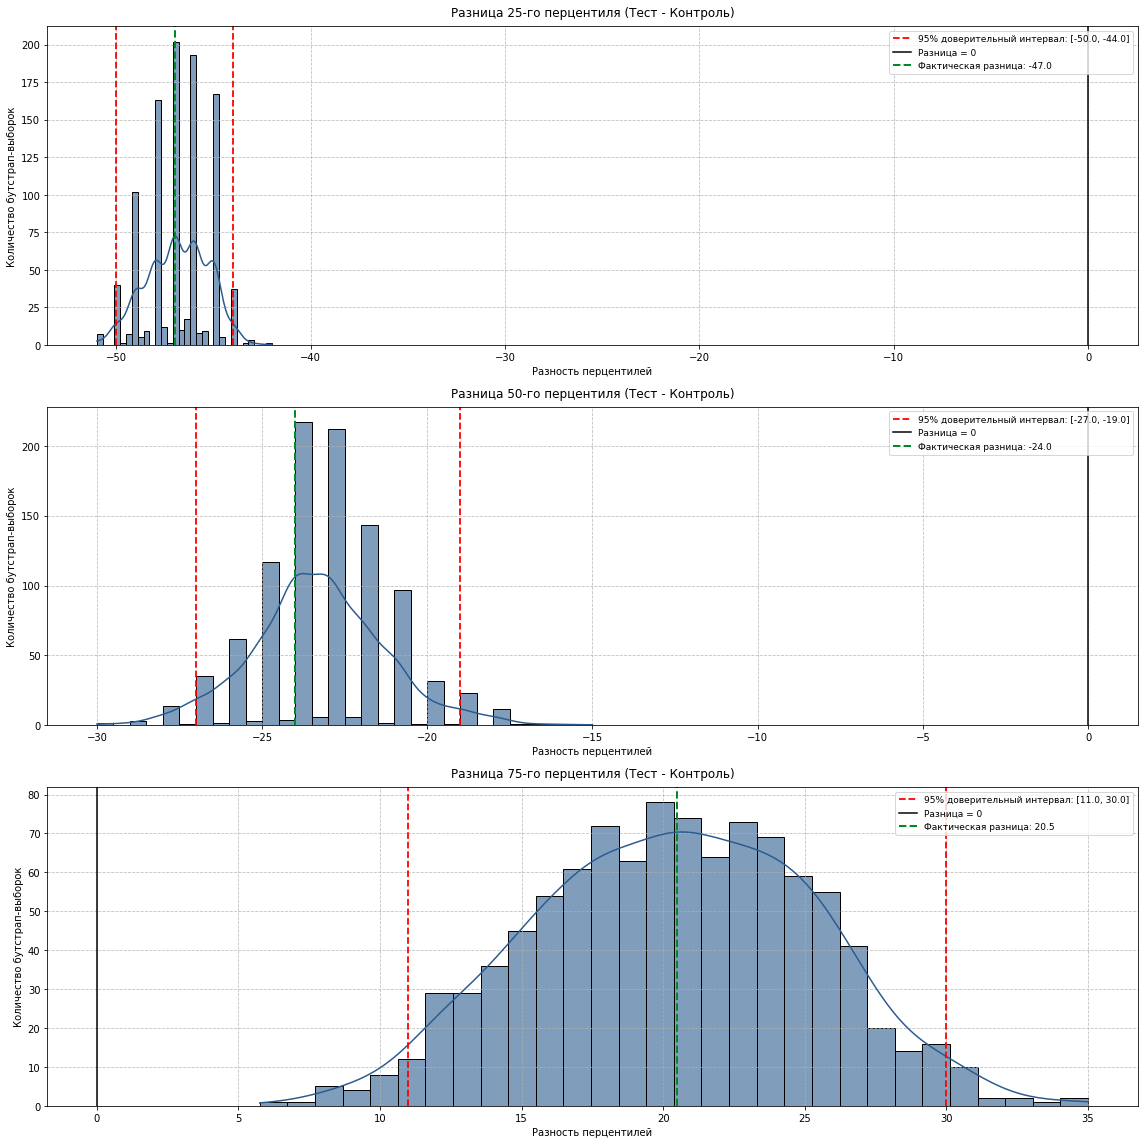

In [54]:
fig, axes = plt.subplots(3, 1, figsize=(16, 16))

percentiles_data = [
    (boot_diffs_25, 25, ci_25, p25_t - p25_c, axes[0]),
    (boot_diffs_50, 50, ci_50, p50_t - p50_c, axes[1]),
    (boot_diffs_75, 75, ci_75, p75_t - p75_c, axes[2])
]

for diffs, p_num, ci, actual_diff, ax in percentiles_data:
    sns.histplot(diffs, ax=ax, color='#2b5c8f', kde=True, alpha=0.6, bins=30)
    ax.axvline(ci[0], color='#FF0000', linestyle='--', linewidth=1.8, label=f'95% доверительный интервал: [{ci[0]:.1f}, {ci[1]:.1f}]')
    ax.axvline(ci[1], color='#FF0000', linestyle='--', linewidth=1.8)
    ax.axvline(0, color='black', linestyle='-', linewidth=1.5, label='Разница = 0')
    ax.axvline(actual_diff, color='#008A24', linestyle='--', linewidth=2, label=f'Фактическая разница: {actual_diff:.1f}')
    
    ax.set_title(f'Разница {p_num}-го перцентиля (Тест - Контроль)', fontsize=12, pad=10)
    ax.set_xlabel('Разность перцентилей', fontsize=10)
    ax.set_ylabel('Количество бутстрап-выборок', fontsize=10)
    ax.legend(fontsize=9, loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.8)

plt.tight_layout()
plt.show()

**Промежуточный вывод:**

Получается, что новый онбординг по-разному повлиял на разные категории платящих пользователей. Если смотреть на нижнюю границу (25-й перцентиль), то в тестовой группе она заметно ниже - разница от -50 до -44, и весь доверительный интервал отрицательный. То есть те, кто раньше вносил небольшие суммы (порядка 95), теперь стали вносить гораздо меньше (около 48). Это как раз подтверждает опасение: часть осторожных пользователей, возможно, испугалась рисков и уменьшила вложения, либо совсем ушла с небольшими суммами.

Медиана (50-й перцентиль) тоже просела - разница в районе -27, -19, тоже значимо ниже. Значит, середина аудитории в тестовой группе платит меньше, чем в контрольной.

А вот верхний сегмент (75-й перцентиль) вырос - разница от +11 до +30, весь интервал положительный. Крупные инвесторы стали вносить ещё больше (в среднем 179 против 159). Это подтверждает, что обучение помогает вовлечённым пользователям чувствовать себя увереннее и увеличивать вложения.

Новый онбординг работает неоднородно. Он отпугнул или снизил активность мелких и средних плательщиков, но привлёк и усилил крупных. Средний чек в целом вырос (мы это видели раньше), но теперь понятно, что рост идёт за счёт верхнего сегмента, а не всей массы. Это важный инсайт, возможно, нужно доработать онбординг, чтобы не терять нижнюю часть аудитории, которая боится рисков.

### Вывод по итогам A/B-эксперимента

---

- Эксперимент показал, что новый обучающий онбординг не дал значимого эффекта на ключевую метрику - средняя сумма депозитов на пользователя осталась на том же уровне (92,46 в тесте против 90,24 в контроле, p = 0,338). Барьерная метрика - конверсия в первый депозит - тоже не изменилась (70,0% против 71,5%, p = 0,121). То есть гипотеза риска не подтвердилась: обучение не отпугнуло новичков от первого пополнения, но и не помогло быстрее решиться на первый платёж.

- При этом гипотеза роста частично подтвердилась по дополнительным метрикам: конверсия из первого депозита во второй выросла с 20,3% до 32,6% (p < 0,001), а средняя сумма депозитов у платящих увеличилась с 135,5 до 141,4 (p = 0,040). Оба эффекта значимы и устойчивы. Обучение действительно повышает вовлечённость и удержание среди тех, кто уже совершил первый платёж.

- **Ключевой инсайт:** онбординг работает неоднородно. Анализ перцентилей показал, что обучение отпугнуло нижнюю часть аудитории - мелкие вкладчики (25-й перцентиль) снизили суммы почти вдвое (с 95 до 48), медиана тоже просела (с 118 до 94). При этом крупные инвесторы (75-й перцентиль) стали вкладывать больше (с 159 до 179,5). Рост среднего чека обеспечивается исключительно верхним сегментом, тогда как массовый платящий пользователь платит меньше. Это подтверждает риск из гипотезы: обучение повышает ценность сильных пользователей, но снижает вклад более консервативной части.

**Рекомендации:**

1. **Внедрять фичу не стоит в текущем виде.** Ключевая метрика не выросла, а нижняя часть аудитории теряет в суммах.
2. **Нужно доработать онбординг.** Снизить пугающий эффект для осторожных пользователей - смягчить подачу информации о рисках, добавить поддержку или адаптивное обучение в зависимости от поведения.
3. **Оставить механику обучения для вовлечённых пользователей.** Она отлично повышает удержание и средний чек среди тех, кто уже готов инвестировать.
4. **Нужно поработать над улучшением конверсии в первый депозит.** Даже небольшое улучшение конверсии в первый депозит даст значительный прирост выручки.

**Главный риск** - потеря мелких и средних плательщиков. Новый онбординг требует доработки перед полным запуском.